# v2 — Native categoricals, geo-imputation, missingness flags, class weights, tuned-by-hand params

**v2 changed five things at once.** The original write-up credits the whole bundle. This notebook adds them **cumulatively, one at a time**, on identical folds, so each step's contribution (and noise) is visible.

| step | adds | hypothesis |
|---|---|---|
| A | v1 leak-free (from the v1 notebook) | — |
| +B | native categorical XGBoost, all features, bools → numeric | H2 |
| +C | region-median imputation (instead of global median) | H3 |
| +D | missingness-indicator flags | H4 |
| +E | v2's XGBoost params (400 trees, lr 0.05, subsample/colsample 0.8) | — |
| +F | balanced class weights | H5 |
| +G *(audit extra, not in v2)* | fix the latitude placeholder `-2e-8` | H1 |

Step +F gives exactly the shipped v2.

In [1]:
import sys, warnings
sys.path.insert(0, '.')
warnings.simplefilter('ignore')
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from common import *
pd.set_option('display.width', 140)
V1, V2 = load_version('v1'), load_version('v2')
df, y, le = get_train('v2')
P1 = dict(n_estimators=300, max_depth=8, learning_rate=0.1)
P2 = dict(n_estimators=400, max_depth=8, learning_rate=0.05, subsample=0.8, colsample_bytree=0.8)

class Flex(V2.FeaturePipeline):
    """v2's FeaturePipeline with each v2 addition switchable."""
    def __init__(self, geo=True, flags=True, fix_lat=False):
        self.geo, self.flags, self.fix_lat = geo, flags, fix_lat
    def _run(self, df, fit):
        if self.fix_lat:                                    # latitude placeholder is -2e-8, not 0
            df = df.copy(); df['latitude'] = df['latitude'].where(df['latitude'] < -1e-4)
        if self.flags: df = self._add_missingness_flags(df, fit)
        elif fit: self.flag_cols_ = []
        if self.geo: df = self._impute_geo_numeric(df, fit)   # else the global-median imputer below handles it
        df = self._add_pump_age(df)
        df = self._impute_categorical(df, fit)
        df = self._impute_numeric(df, fit)
        df = self._cast_categoricals(df, fit)
        if fit: self.feature_cols_ = list(df.columns)
        return df[self.feature_cols_]

def run(label, make_features, params, balanced=False, **kw):
    sc, oof = cv_xgb(df, y, make_features, params, balanced=balanced, **kw)
    r = log_result('v2', label, sc); print(f"{label:<44} {r['mean']:.4f} ± {r['std']:.4f}")
    return sc, oof

## A — v1 baseline, leak-free (re-run live on these folds)

In [2]:
dfa, ya, _ = get_train('v1')
sc, _ = cv_xgb(dfa, ya, V1.FeaturePipeline, P1, y_to_features=True)
r = log_result('v2', 'A  v1 leak-free', sc); print(f"{r['mean']:.4f} ± {r['std']:.4f}")

0.8034 ± 0.0044


## +B — native categoricals (no frequency encoding, no top-15 cut)

In [3]:
_ = run('+B native categoricals', lambda: Flex(geo=False, flags=False), P1)

+B native categoricals                       0.8010 ± 0.0033


## +C — region-median imputation

In [4]:
_ = run('+C region-median impute', lambda: Flex(geo=True, flags=False), P1)

+C region-median impute                      0.8005 ± 0.0032


## +D — missingness flags

In [5]:
_ = run('+D missingness flags', lambda: Flex(geo=True, flags=True), P1)

+D missingness flags                         0.8008 ± 0.0042


## +E — v2's XGBoost hyperparameters

In [6]:
sc_e, oof_e = run('+E v2 params', lambda: Flex(), P2)

+E v2 params                                 0.7979 ± 0.0038


## +F — balanced class weights (this equals shipped v2)

In [7]:
sc_f, oof_f = run('+F balanced weights  (= v2)', lambda: Flex(), P2, balanced=True)

+F balanced weights  (= v2)                  0.7772 ± 0.0034


## +G — audit extra: fix the latitude placeholder (H1)

In [8]:
sc_g, oof_g = run('+G latitude fix (extra)', lambda: Flex(fix_lat=True), P2, balanced=True)

+G latitude fix (extra)                      0.7766 ± 0.0033


## Results: the ablation table

In [9]:
import json
res = pd.DataFrame([r for r in map(json.loads, RESULTS.read_text().splitlines()) if r['version'] == 'v2'])
res['delta vs prev'] = res['mean'].diff().round(4)
res['noise (fold std)'] = res['std'].round(4)
res['acc'] = res['mean'].round(4)
res[['label', 'acc', 'delta vs prev', 'noise (fold std)']].set_index('label')

,acc,delta vs prev,noise (fold std)
label,,,
A v1 leak-free,0.8034,NaN,0.0044
+B native categoricals,0.8010,-0.0024,0.0033
+C region-median impute,0.8005,-0.0005,0.0032
+D missingness flags,0.8008,0.0003,0.0042
+E v2 params,0.7979,-0.0029,0.0038
+F balanced weights (= v2),0.7772,-0.0206,0.0034
+G latitude fix (extra),0.7766,-0.0006,0.0033


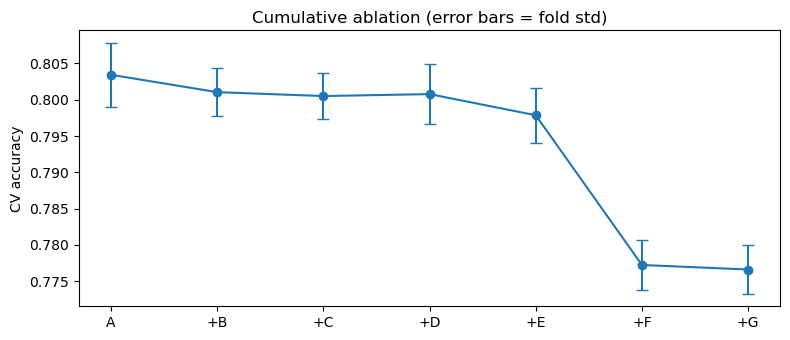

In [10]:
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.errorbar(range(len(res)), res['mean'], yerr=res['std'], fmt='o-', capsize=4)
ax.set_xticks(range(len(res))); ax.set_xticklabels([l.split()[0] for l in res.label]); ax.set_ylabel('CV accuracy')
ax.set_title('Cumulative ablation (error bars = fold std)'); plt.tight_layout(); plt.show()

## Error analysis: what do class weights (+F) actually do? (H5)

In [11]:
from sklearn.metrics import recall_score, precision_score
rows = []
for name, o in [('+E (no weights)', oof_e), ('+F (balanced weights)', oof_f), ('+G (+ lat fix)', oof_g)]:
    rows.append({'model': name, 'acc': (o == y).mean(), **{f'recall[{c}]': v for c, v in zip(le.classes_, recall_score(y, o, average=None))}})
pd.DataFrame(rows).set_index('model').round(4)

,acc,recall[functional],recall[functional needs repair],recall[non functional]
model,,,,
+E (no weights),0.7979,0.8814,0.3299,0.7684
+F (balanced weights),0.7772,0.8128,0.4739,0.7843
+G (+ lat fix),0.7766,0.8114,0.4742,0.7847


## Conclusion

| step | CV accuracy | Δ vs previous | verdict |
|---|---|---|---|
| A  v1 leak-free | 0.8034 ± 0.0044 | — | baseline (0.8090 without its MI cut, see v1 notebook) |
| +B native categoricals | 0.8010 ± 0.0033 | −0.0024 | no gain; below A, and below v1's 0.8090 no-cut row |
| +C region-median impute | 0.8005 ± 0.0032 | −0.0005 | noise (H3 not supported) |
| +D missingness flags | 0.8008 ± 0.0042 | +0.0003 | noise (H4 not supported) |
| +E v2 params | 0.7979 ± 0.0038 | −0.0029 | slightly worse than v1's params |
| **+F balanced weights (= v2 as shipped)** | **0.7772 ± 0.0034** | **−0.0206** | **clear loss, ≈ 6× the fold std; negative on all 5 folds** |
| +G latitude fix (extra) | 0.7766 ± 0.0033 | −0.0006 | noise (H1 not supported here) |

**The headline: v2 as shipped is *worse* than the v1 baseline on the competition metric** (0.777 vs 0.803, and 0.809 for v1 without the MI cut). Not one of the five v2 changes improved accuracy beyond noise.

- **H5 is confirmed, and it dominates.** Balanced weights lift *needs repair* recall from 0.33 to 0.47 and *non functional* slightly (0.768 → 0.784), but *functional* recall falls 0.881 → 0.813. The metric is plain accuracy and the majority class is 54%, so reweighting trades away the metric for a class that barely counts in it. Weights would be right for macro-F1, but that isn't the score here.
- **H2 (native categoricals), H3 (region median) and H4 (flags) are not supported.** Each is within noise of its predecessor. +B is below even v1 with its top-15 cut.
- **H1 (latitude fix) is not supported** for this model: −0.0006, noise. The bug is real, but trees seem to cope with 1,812 bad rows (3%) or the other geo columns compensate. It may still matter for v4's `geo_cluster`, which I haven't tested.
- **Caveats.** (1) This is one seed and one fold scheme, and random folds may be optimistic compared with the leaderboard. (2) +B changes two things at once, native categoricals and the removed top-15 cut. I haven't separated them, and the v1 notebook suggests the cut removal alone is worth +0.0056, so native encoding itself may be around −0.008. (3) These are CV numbers, not leaderboard scores.

**Implication for the project.** `SUMMARY.md` calls v7 the "last and strongest version", but every later version (v3–v7) keeps +F's balanced weights, and none has recorded an accuracy. Hypothesis for the v3 notebook: **dropping the weights is worth more than any later feature**. Test v3–v7 both with and without weights, starting from v1's 0.809 as the bar.